# Penguins: your first tree models
**Beginner workshop · Session 4 · 90–120 minutes**

We will predict a penguin’s **species** using four body measurements. We will train a decision tree, a random forest and gradient boosting on the same data.

**Our routine:** understand the idea → run the example → complete a small task.

All visualization code is supplied. Exercises involve one to four lines or changing a parameter. You will not implement algorithms, write plotting functions or perform grid search. Each TODO has a hint directly above it. The final comparison runs even if exercises are unfinished.

**Libraries:** pandas, NumPy, scikit-learn and Matplotlib. Python’s standard library is used only for downloading the data. No GPU is needed.

**Source:** the [Kaggle notebook you selected](https://www.kaggle.com/code/bensparksmei/penguin-data-decision-tree-classifier) uses [`larsen0966/penguins`](https://www.kaggle.com/datasets/larsen0966/penguins). This notebook loads that exact dataset. The original example starts with Gentoo versus other penguins; here we predict all three species so the final comparison remains a classification exercise.

The data were collected by Kristen Gorman and the Palmer Station LTER program. See the [Palmer Penguins documentation](https://allisonhorst.github.io/palmerpenguins/) for measurement definitions.

## 1. Understand every column
Each row describes one penguin. A **feature** is an input we give the model. The **target** is the answer it learns to predict.

| Column | Plain-language meaning | Type / unit | Role in this lesson |
|---|---|---|---|
| `species` | The kind of penguin: Adelie, Chinstrap or Gentoo. These are three species, not male/female categories. | Category | **Target** |
| `island` | Island where the penguin was observed: Biscoe, Dream or Torgersen, in Antarctica’s Palmer Archipelago. | Category | Explained and explored; not a model input |
| `bill_length_mm` | Length of the beak (bill), from its base toward its tip. Also called culmen length in some versions. | Number, millimetres | Input |
| `bill_depth_mm` | Top-to-bottom thickness of the beak near its base. This is its depth, not its length or side-to-side width. | Number, millimetres | Input |
| `flipper_length_mm` | Length of the flattened wing used for swimming. | Number, millimetres | Input |
| `body_mass_g` | Body mass of the penguin. For example, 4,000 g = 4 kg. | Number, grams | Input |
| `sex` | Recorded biological sex: male or female. Some entries are missing. | Category | Explained; not a model input |
| `year` | Year of observation: 2007, 2008 or 2009. It is **not the penguin’s age**. | Calendar year | Explained; not a model input |
| `Unnamed: 0` | An exported row index in this particular CSV. It identifies the row, not a biological measurement. | Integer identifier | Remove |

For one example penguin, a bill length of 39.1 mm means a beak about 3.91 cm long. A flipper length of 181 mm means 18.1 cm. Numeric values use different units, but decision trees do not require standardization.

We start with the four numeric body measurements to keep the code easy to read. Island and sex would need categorical encoding if added later. **Never include species, or a species-derived flag such as gentoo, among the inputs when predicting species.** That would reveal the answer.

In [1]:
# Run only if these libraries are missing, then restart the kernel:
# %pip install pandas numpy scikit-learn matplotlib

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
SEED = 42
plt.rcParams['figure.figsize'] = (8, 4)

## 2. Load the dataset
Run this supplied setup cell. It first looks for a local `penguins.csv` or the Kaggle input location. Otherwise, it downloads the original Kaggle dataset. The first download needs internet. If downloading is blocked, download `penguins.csv` from the dataset page and place it next to the notebook. You do not need to understand the download code for this lesson.

In [4]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO

paths = [Path('penguins.csv'), Path('/kaggle/input/penguins/penguins.csv')]
local_file = next((path for path in paths if path.exists()), None)
if local_file is not None:
    penguins = pd.read_csv(local_file)
else:
    url = 'https://www.kaggle.com/api/v1/datasets/download/larsen0966/penguins'
    with urlopen(url, timeout=60) as response:
        archive = ZipFile(BytesIO(response.read()))
    penguins = pd.read_csv(archive.open('penguins.csv'))

# Remove the exported row index, if present.
penguins = penguins.drop(columns=['Unnamed: 0'], errors='ignore')
print('Rows and columns:', penguins.shape)
print(penguins.head().to_string(index=False))

Rows and columns: (344, 8)
species    island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g    sex  year
 Adelie Torgersen            39.1           18.7              181.0       3750.0   male  2007
 Adelie Torgersen            39.5           17.4              186.0       3800.0 female  2007
 Adelie Torgersen            40.3           18.0              195.0       3250.0 female  2007
 Adelie Torgersen             NaN            NaN                NaN          NaN    NaN  2007
 Adelie Torgersen            36.7           19.3              193.0       3450.0 female  2007


`head()` shows the first five rows. `shape` gives (number of rows, number of columns). `info()` shows column types and non-missing counts. `NaN` means a measurement was not recorded; it does not mean zero.

In [6]:
penguins = penguins.sample(frac=1, random_state=SEED).reset_index(drop=True)
print("Shuffled dataset shape:", penguins.shape)

Shuffled dataset shape: (344, 8)


In [5]:
penguins.info()
print('Missing values per column:')
print(penguins.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB
Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


### Practice 1
Show the first 10 rows. Then display the three species names.

**Hint**
Use .head(10) and penguins["species"].unique(). Wrap each expression in print().

In [7]:
penguins = penguins.sample(frac=1, random_state=SEED).reset_index(drop=True)
print("shuffles dataset shape :",penguins.shape)
print(penguins.head(10))
print(penguins['species'].unique())

shuffles dataset shape : (344, 8)
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie     Biscoe            38.2           20.0              190.0   
1  Gentoo     Biscoe            50.4           15.3              224.0   
2  Gentoo     Biscoe            46.5           14.4              217.0   
3  Adelie  Torgersen            41.1           17.6              182.0   
4  Adelie      Dream            36.0           17.9              190.0   
5  Adelie      Dream            37.8           18.1              193.0   
6  Gentoo     Biscoe            50.0           15.9              224.0   
7  Gentoo     Biscoe            40.9           13.7              214.0   
8  Adelie  Torgersen            36.6           17.8              185.0   
9  Gentoo     Biscoe            45.1           14.4              210.0   

   body_mass_g     sex  year  
0       3900.0    male  2009  
1       5550.0    male  2008  
2       4900.0  female  2008  
3       3200.0  female  200

## 3. Choose X and y, and handle missing values
`X` contains the questions we can ask: the four body measurements. `y` contains the answer: species.

For this introductory lesson, remove rows missing any of these five required values. We do not remove rows just because sex is missing, since sex is not an input. This leaves 342 penguins. Dropping missing rows is a simple teaching choice; for other datasets it can discard useful data or bias the sample.

In [8]:
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
clean = penguins.dropna(subset=features + ['species']).copy()
X = clean[features]
y = clean['species']
print('Rows removed:', len(penguins) - len(clean))
print('X shape:', X.shape)
print('Target values:', y.unique())

Rows removed: 2
X shape: (342, 4)
Target values: ['Adelie' 'Gentoo' 'Chinstrap']


### Practice 2
Calculate the average body mass of the retained penguins in grams and in kilograms.

**Hint**
Use clean["body_mass_g"].mean(). Divide the answer by 1000 to convert grams to kilograms.

In [9]:
# TODO 2
average_g = clean["body_mass_g"].mean()
print(average_g)
print(average_g / 1000)

4201.754385964912
4.201754385964912


## 4. Keep separate data for learning and checking
We use 60% for training, 20% for validation and 20% for the final test.

- **Training:** the model learns its rules.
- **Validation:** we try a few tree depths.
- **Test:** we evaluate the finished models at the end.

`stratify=y` keeps similar species proportions in each part. `random_state=42` makes the split reproducible. We explore relationships in the training subset so our final test remains reserved.

In [10]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED
)
print('Training:', len(X_train), 'Validation:', len(X_val), 'Test:', len(X_test))
# A table for exploring training examples only.
training = X_train.assign(species=y_train)

Training: 204 Validation: 69 Test: 69


## 5. Look at patterns • plotting code supplied
Run the next plots and describe what you see. No plotting implementation is required. A class-count plot shows how many examples we have. A scatter plot shows whether two measurements help separate species.

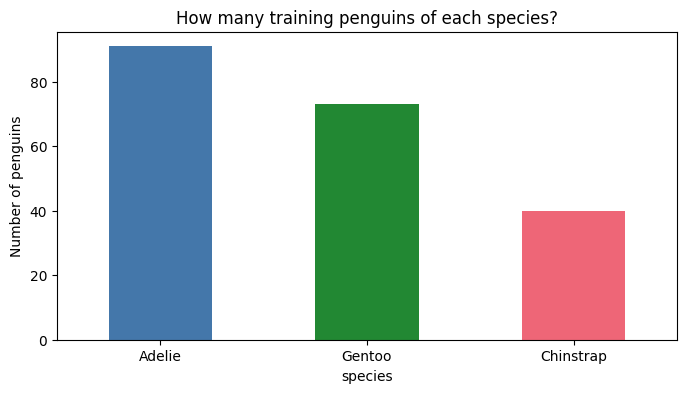

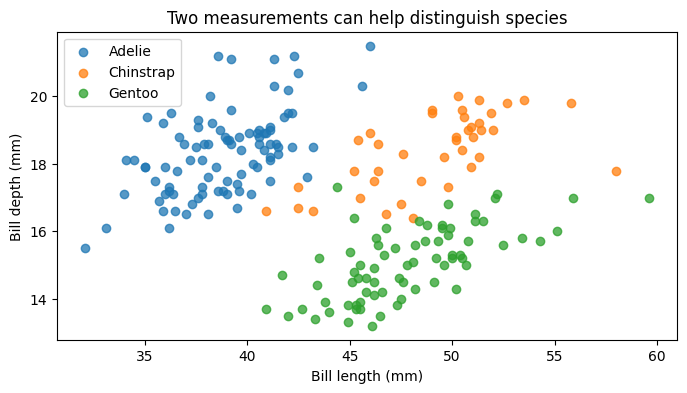

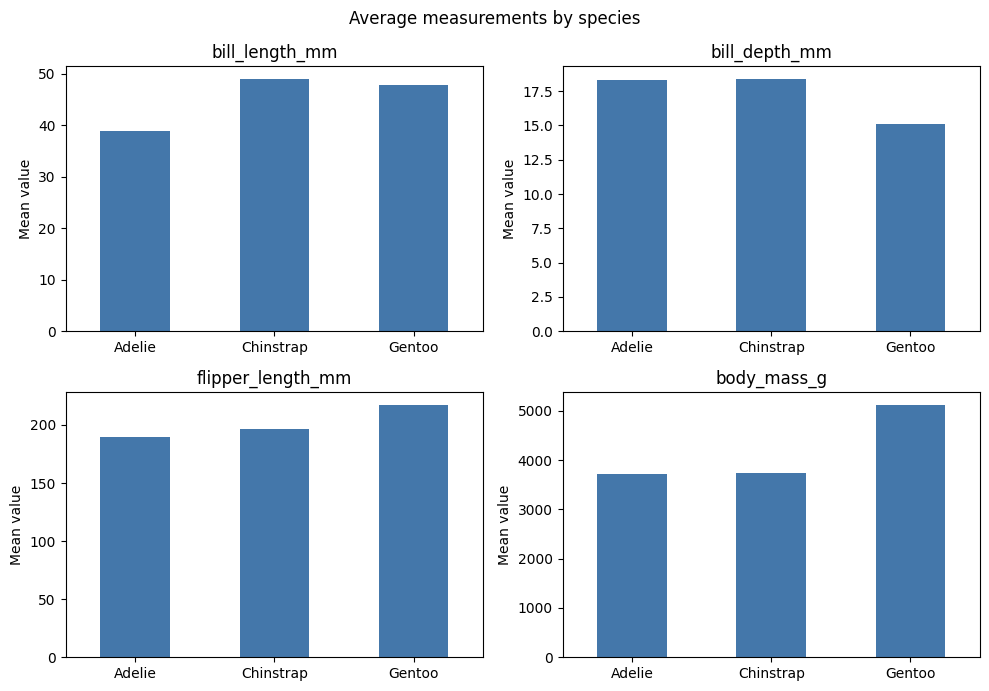

In [11]:
training['species'].value_counts().plot.bar(color=['#4477AA', '#228833', '#EE6677'], rot=0)
plt.title('How many training penguins of each species?')
plt.ylabel('Number of penguins')
plt.show()

for species, group in training.groupby('species'):
    plt.scatter(group['bill_length_mm'], group['bill_depth_mm'], label=species, alpha=0.75)
plt.xlabel('Bill length (mm)')
plt.ylabel('Bill depth (mm)')
plt.title('Two measurements can help distinguish species')
plt.legend()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, feature in zip(axes.flat, features):
    training.groupby('species')[feature].mean().plot.bar(ax=ax, rot=0, color='#4477AA')
    ax.set_title(feature)
    ax.set_ylabel('Mean value')
    ax.set_xlabel('')
plt.suptitle('Average measurements by species')
plt.tight_layout()
plt.show()

### Practice 3
Print the average flipper length for each species. Which species has the largest average in the training data?

**Hint**
Use training.groupby("species")["flipper_length_mm"].mean(). Read the values; no plot is needed.

In [ ]:
# TODO 3
# print(training.groupby(...)[...].mean())

species
Adelie       189.989011
Chinstrap    196.425000
Gentoo       217.219178
Name: flipper_length_mm, dtype: float64


## 6. How a decision tree makes a prediction
A tree asks questions such as “Is flipper length ≤ 206.5 mm?” Each answer sends the penguin to a smaller group. A **leaf** is the final group; it predicts the most common training species in that group.

`DecisionTreeClassifier(...)` creates the model. `max_depth=3` allows at most three questions along a path. `fit(X_train, y_train)` learns the rules. `predict(X_val)` applies those rules to new examples. The model finds the features and thresholds automatically.

Validation accuracy: 0.9420289855072463


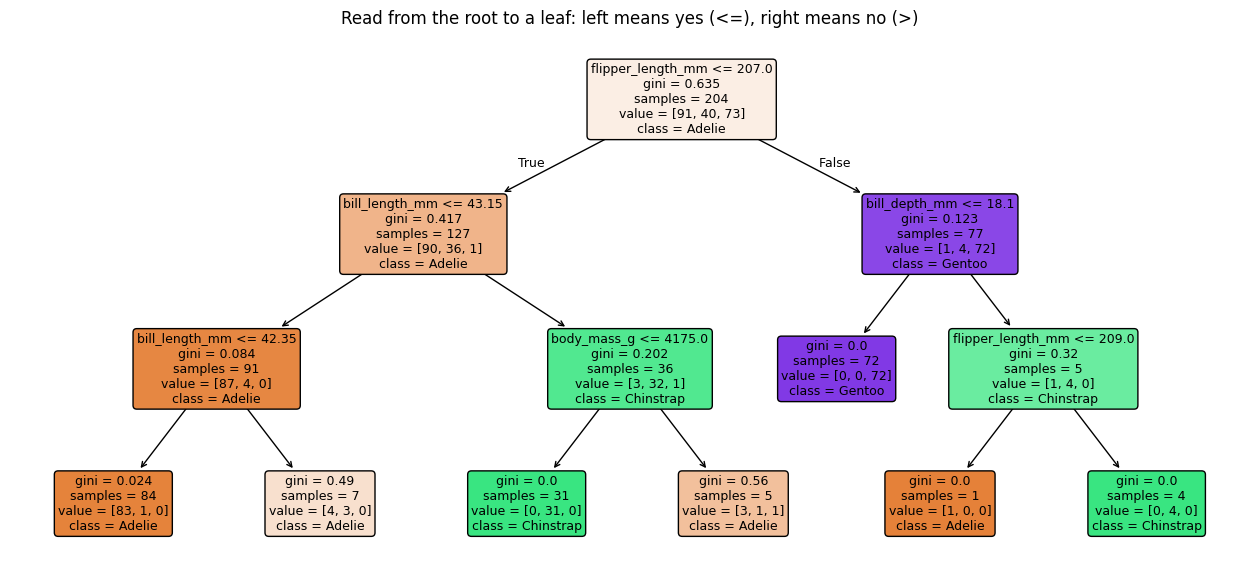

In [ ]:
tree = DecisionTreeClassifier(max_depth=3, random_state=SEED)
tree.fit(X_train, y_train)
val_predictions = tree.predict(X_val)
print('Validation accuracy:', accuracy_score(y_val, val_predictions))

plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=features, class_names=tree.classes_,
          filled=True, rounded=True, fontsize=9)
plt.title('Read from the root to a leaf: left means yes (<=), right means no (>)')
plt.show()

How to read a node:
- **First line:** the measurement and threshold.
- **gini:** how mixed the species are; zero means only one species.
- **samples:** number of training penguins reaching that node.
- **value:** class counts (or proportions, depending on scikit-learn version), in `tree.classes_` order.
- **class:** the prediction at that node.

Before running the next cell, follow the displayed penguin through the plotted tree.

In [ ]:
one_penguin = X_val.iloc[[0]]  # Double brackets keep a table with one row.
print(one_penguin.to_string(index=False))
print('Actual species:', y_val.iloc[0])
print('Predicted species:', tree.predict(one_penguin)[0])
print(pd.Series(tree.predict_proba(one_penguin)[0], index=tree.classes_))

 bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
           37.7           19.8              198.0       3500.0
Actual species: Adelie
Predicted species: Adelie
Adelie       0.988095
Chinstrap    0.011905
Gentoo       0.000000
dtype: float64


### Practice 4
Predict the species of the second validation penguin and compare it with the actual species.

**Hint**
Use X_val.iloc[[1]], tree.predict(...) and y_val.iloc[1]. Python positions start at zero.

In [ ]:
# TODO 4
# second_penguin = ...
# print(tree.predict(...))
# print(y_val.iloc[...])

## 7. What makes a split good? • concept demonstration
A good split puts similar species together. **Gini** and **entropy** measure how mixed a group is. A pure group has impurity zero. For Gini: `1 - sum(class_proportions ** 2)`.

We demonstrate with two species to keep the arithmetic short. Real penguin nodes can contain three species. The tree handles the calculation for us. Students do not need to write a split-search algorithm.

Gini for a 50/50 group: 0.5
Gini for a pure group: 0.0


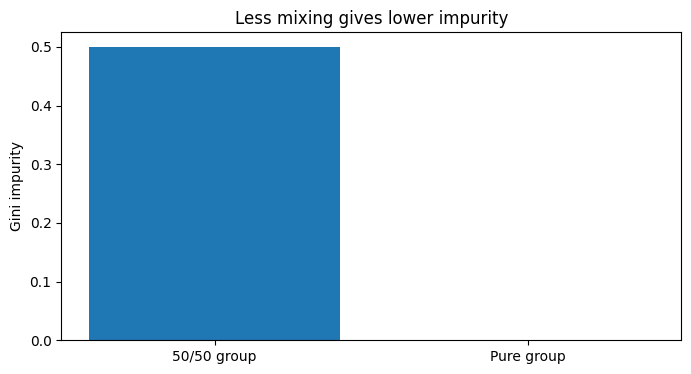

In [ ]:
mixed = np.array([0.5, 0.5])
pure = np.array([1.0, 0.0])
print('Gini for a 50/50 group:', 1 - np.sum(mixed ** 2))
print('Gini for a pure group:', 1 - np.sum(pure ** 2))
plt.bar(['50/50 group', 'Pure group'], [1 - np.sum(mixed ** 2), 1 - np.sum(pure ** 2)])
plt.ylabel('Gini impurity')
plt.title('Less mixing gives lower impurity')
plt.show()

**Information gain** = parent entropy − weighted average of child entropies. Gini reduction uses the same idea with Gini. Weight each child by its fraction of examples. A tree tries candidate questions and keeps the largest reduction.

**Brief regression reminder:** a regression tree predicts a number rather than a species. With squared error, each leaf predicts its mean target; splits reduce the spread of numeric targets. All models in the rest of this notebook are classifiers.

### Practice 5
Calculate Gini for a group containing 80% Adelie and 20% Chinstrap. Is it less mixed than 50/50?

**Hint**
Set p = np.array([0.8, 0.2]), then calculate 1 - np.sum(p ** 2). Expected answer: 0.32.

In [ ]:
# TODO 5
# p = ...
# print(...)

## 8. Too simple or too complicated?
A shallow tree can miss useful patterns (**underfitting**). A very deep tree may memorize training examples (**overfitting**). Compare training and validation accuracy. A higher training score alone is not enough.

This supplied code compares only three depths. The bar plot helps you read the results; you do not need to write plotting code.

 depth  train_accuracy  validation_accuracy
     1        0.794118             0.797101
     3        0.970588             0.942029
     8        1.000000             0.971014


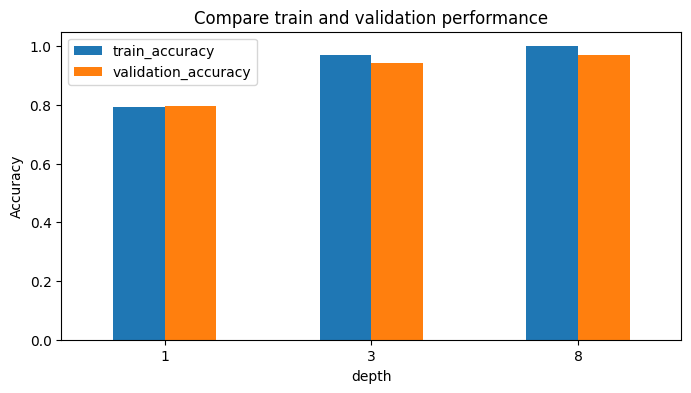

Chosen depth: 8


In [ ]:
depth_results = []
for depth in [1, 3, 8]:
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    candidate.fit(X_train, y_train)
    depth_results.append({'depth': depth,
                          'train_accuracy': candidate.score(X_train, y_train),
                          'validation_accuracy': candidate.score(X_val, y_val)})
depth_results = pd.DataFrame(depth_results)
print(depth_results.to_string(index=False))
depth_results.set_index('depth').plot.bar(ylim=(0, 1.05), rot=0)
plt.ylabel('Accuracy')
plt.title('Compare train and validation performance')
plt.show()
# Choose using validation only; ties favor the first (shallower) depth.
best_depth = int(depth_results.loc[depth_results.validation_accuracy.idxmax(), 'depth'])
print('Chosen depth:', best_depth)

### Practice 6
Train a tree with max_depth=2 and print its validation accuracy.

**Hint**
Copy the three model-building lines: create DecisionTreeClassifier, call fit, then score(X_val, y_val). This is a practice model; the supplied final comparison uses the depth selected above.

In [ ]:
# TODO 6
# practice_tree = DecisionTreeClassifier(max_depth=..., random_state=42)
# practice_tree.fit(..., ...)
# print(practice_tree.score(..., ...))

## 9. Many trees: random forests
A forest trains many trees on different random samples of rows. It also considers random subsets of features at each split. The combined predictions can be more stable than one tree’s predictions. In scikit-learn, a classification forest averages class probabilities.

`n_estimators=100` means 100 trees. The commands `fit`, `predict` and `score` work just as they did for one tree.

In [ ]:
forest = RandomForestClassifier(n_estimators=100, random_state=SEED)
forest.fit(X_train, y_train)
print('Forest validation accuracy:', forest.score(X_val, y_val))

Forest validation accuracy: 0.9855072463768116


### Practice 7
Create a forest with 50 trees, train it and print its validation accuracy.

**Hint**
Copy the example and change only n_estimators to 50. You do not need to build or combine individual trees yourself.

In [ ]:
# TODO 7
# forest_50 = RandomForestClassifier(n_estimators=..., random_state=42)
# forest_50.fit(..., ...)
# print(forest_50.score(..., ...))

## 10. Learning in sequence: gradient boosting
Gradient boosting adds small trees one after another. Each addition tries to improve the current predictions. For classification, it improves a classification loss; it does not subtract species names from predictions.

`n_estimators` is the number of boosting rounds. `learning_rate` controls how large each correction is. `max_depth` limits each small tree. We use fixed beginner settings instead of an advanced parameter search.

In [ ]:
boosting = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=2, random_state=SEED
)
boosting.fit(X_train, y_train)
print('Boosting validation accuracy:', boosting.score(X_val, y_val))

Boosting validation accuracy: 0.9855072463768116


### Practice 8
Train gradient boosting with learning_rate=0.05 and print validation accuracy.

**Hint**
Copy the example, change 0.1 to 0.05, then call fit and score. A smaller learning rate is not automatically better and may need more rounds.

In [ ]:
# TODO 8
# slower_boosting = GradientBoostingClassifier(learning_rate=..., max_depth=2, random_state=42)
# slower_boosting.fit(..., ...)
# print(slower_boosting.score(..., ...))

## 11. Final comparison on the same test data
The next supplied code trains our three models on all development data (training + validation). Every model receives the same four features and the same rows. The decision tree uses the depth chosen on validation; ensemble settings remain those shown above.

We now evaluate the reserved test data once. **Accuracy** is the fraction of correct predictions. **Macro F1** averages F1 across species, giving each species equal weight. This is a small classroom benchmark, not proof that one algorithm is always best. Small datasets can produce ties.

                   Accuracy  Macro F1
Model                                
Decision tree         0.986     0.988
Random forest         0.986     0.988
Gradient boosting     0.971     0.970
Majority-class baseline accuracy: 0.43478260869565216


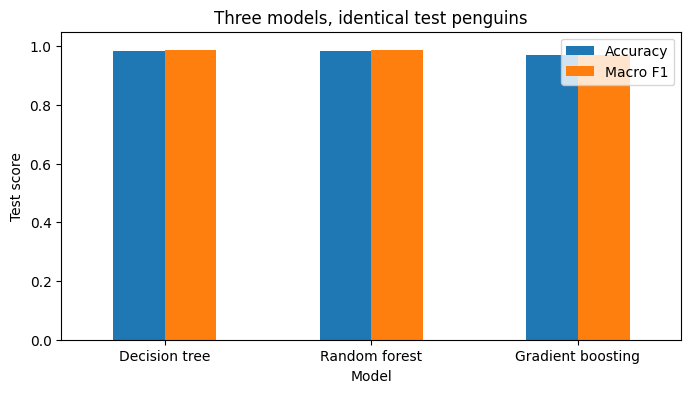

In [ ]:
models = {
    'Decision tree': DecisionTreeClassifier(max_depth=best_depth, random_state=SEED),
    'Random forest': RandomForestClassifier(n_estimators=100, random_state=SEED),
    'Gradient boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=SEED)
}
results = []
for name, model in models.items():
    model.fit(X_dev, y_dev)
    predictions = model.predict(X_test)
    results.append({'Model': name,
                    'Accuracy': accuracy_score(y_test, predictions),
                    'Macro F1': f1_score(y_test, predictions, average='macro')})
results = pd.DataFrame(results).set_index('Model')
print(results.round(3).to_string())
print('Majority-class baseline accuracy:', np.mean(y_test == y_dev.mode()[0]))
results.plot.bar(ylim=(0, 1.05), rot=0)
plt.ylabel('Test score')
plt.title('Three models, identical test penguins')
plt.show()

A **confusion matrix** shows which species the model confused. Rows are actual species; columns are predicted species. Correct predictions lie on the diagonal. The plots are already implemented below.

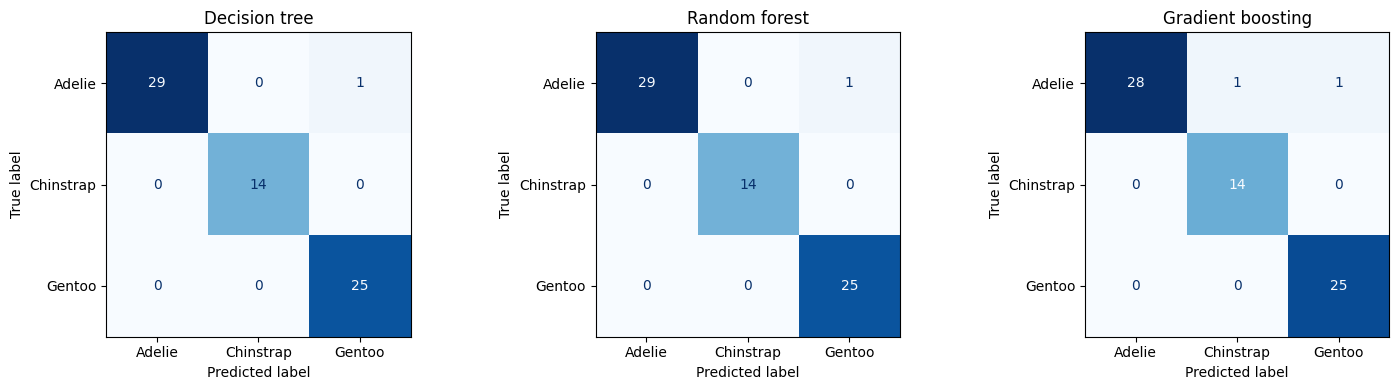

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test), labels=model.classes_,
        ax=ax, colorbar=False, cmap='Blues'
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Practice 9
Read the results and write three sentences: which model had the highest test accuracy (or tied), which species were confused, and why training accuracy alone is insufficient.

**Hint**
Use the results table and off-diagonal confusion-matrix cells. No new code or plot is required. Do not change model settings based on the test results.

In [ ]:
# TODO 9
# Write your answer here as comments, or add a Markdown cell.
# 1. ...
# 2. ...
# 3. ...

## 12. Predict one penguin from measurements
Keep the feature names and order consistent with training. The example below reuses an actual held-out penguin, so we can compare its prediction with a known species.

In [ ]:
new_penguin = X_test.iloc[[0]].copy()
print(new_penguin.to_string(index=False))
for name, model in models.items():
    print(name, 'predicts', model.predict(new_penguin)[0])
print('Actual species:', y_test.iloc[0])

 bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
           37.7           16.0              183.0       3075.0
Decision tree predicts Adelie
Random forest predicts Adelie
Gradient boosting predicts Adelie
Actual species: Adelie


### Practice 10
Use the trained random forest to predict the second test penguin.

**Hint**
Use models["Random forest"].predict(X_test.iloc[[1]]) and compare with y_test.iloc[1]. No retraining is needed.

In [ ]:
# TODO 10
# prediction = ...
# print(prediction)
# print(y_test.iloc[1])

## What students should be able to explain
- Features are inputs; species is the target.
- A decision tree learns questions and ends at a class prediction.
- Lower impurity means less mixing of classes.
- A random forest combines many trees; boosting adds corrections sequentially.
- Validation helps choose settings; the test set checks final performance.

**Teacher pacing:** 20 minutes for columns/loading, 20 for exploration and the first tree, 20 for impurity/depth, 20 for ensembles/comparison, plus time for exercises. Link to presentation slides 3–14 for single-tree concepts, 20–25 for ensembles, and 27–33 for generalization and comparison.

**Scope:** this is deliberately an introductory version. Categorical encoding, imputation pipelines, pruning, detailed split searches and cross-validation can follow in a later workshop. Every exercise here has a worked pattern nearby.

**Data provenance:** [exact Kaggle dataset](https://www.kaggle.com/datasets/larsen0966/penguins), [selected reference notebook](https://www.kaggle.com/code/bensparksmei/penguin-data-decision-tree-classifier), [original dataset documentation](https://allisonhorst.github.io/palmerpenguins/). The data describe the sampled penguins; performance on this split does not guarantee performance in another location or population.